# Bank Term Deposit Prediction
Explore the UCI bank marketing data, compare classifiers, and evaluate the selected model. Place `bank-full.csv` in the project root before running.

In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_preprocessing import load_dataset
from src.eda import create_eda_plots
from src.train_model import train_and_select
from src.evaluate_model import evaluate_model
from src.prediction import predict_records

DATA_PATH = ROOT / 'bank-full.csv'
OUTPUT_DIR = ROOT / 'outputs'
MODEL_DIR = ROOT / 'models'

## Load and inspect data
The loader detects the source file delimiter and converts the yes/no target to 1/0.

In [2]:
X, y = load_dataset(DATA_PATH, target='y')
display(X.head())
print(f'Rows: {len(X):,}; features: {X.shape[1]}')
display(y.value_counts().rename(index={0: 'no', 1: 'yes'}).to_frame('customers'))

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown


Rows: 45,211; features: 16


,customers
y,
no,39922
yes,5289


## Exploratory analysis
Review subscription distribution, age, and job-level subscription rates.

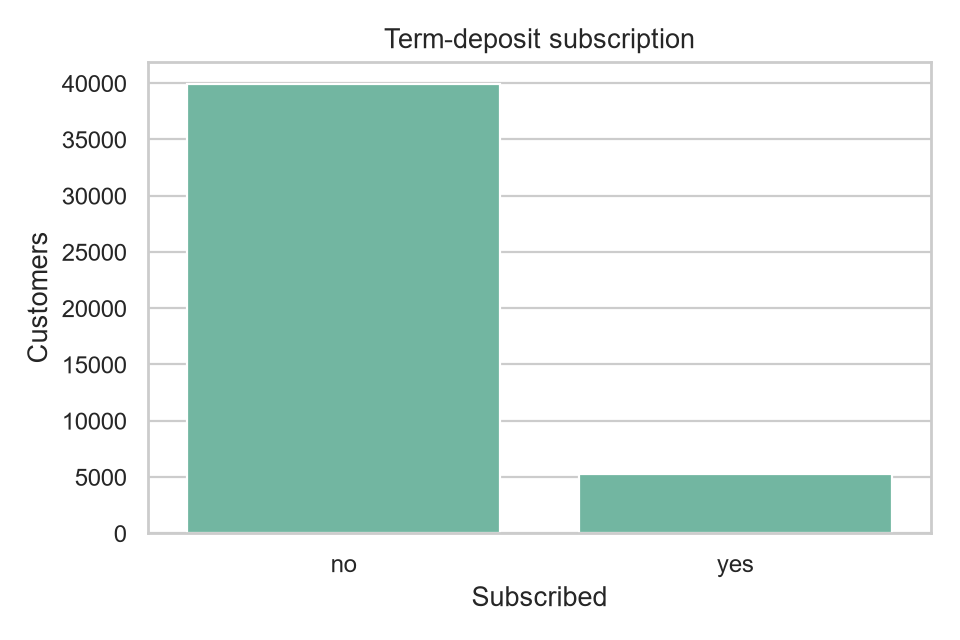

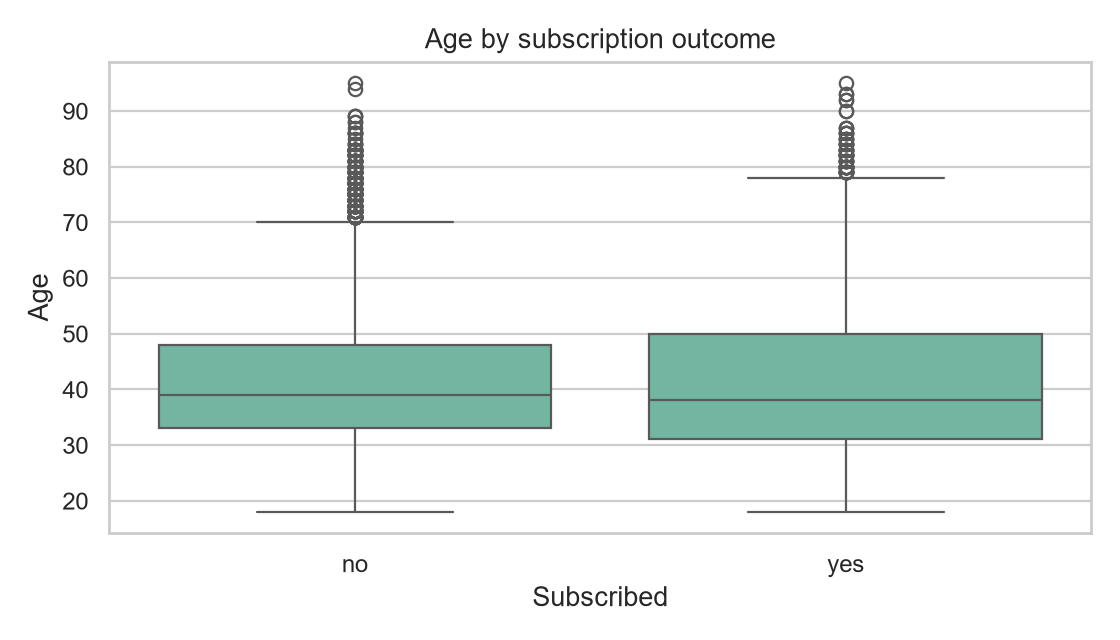

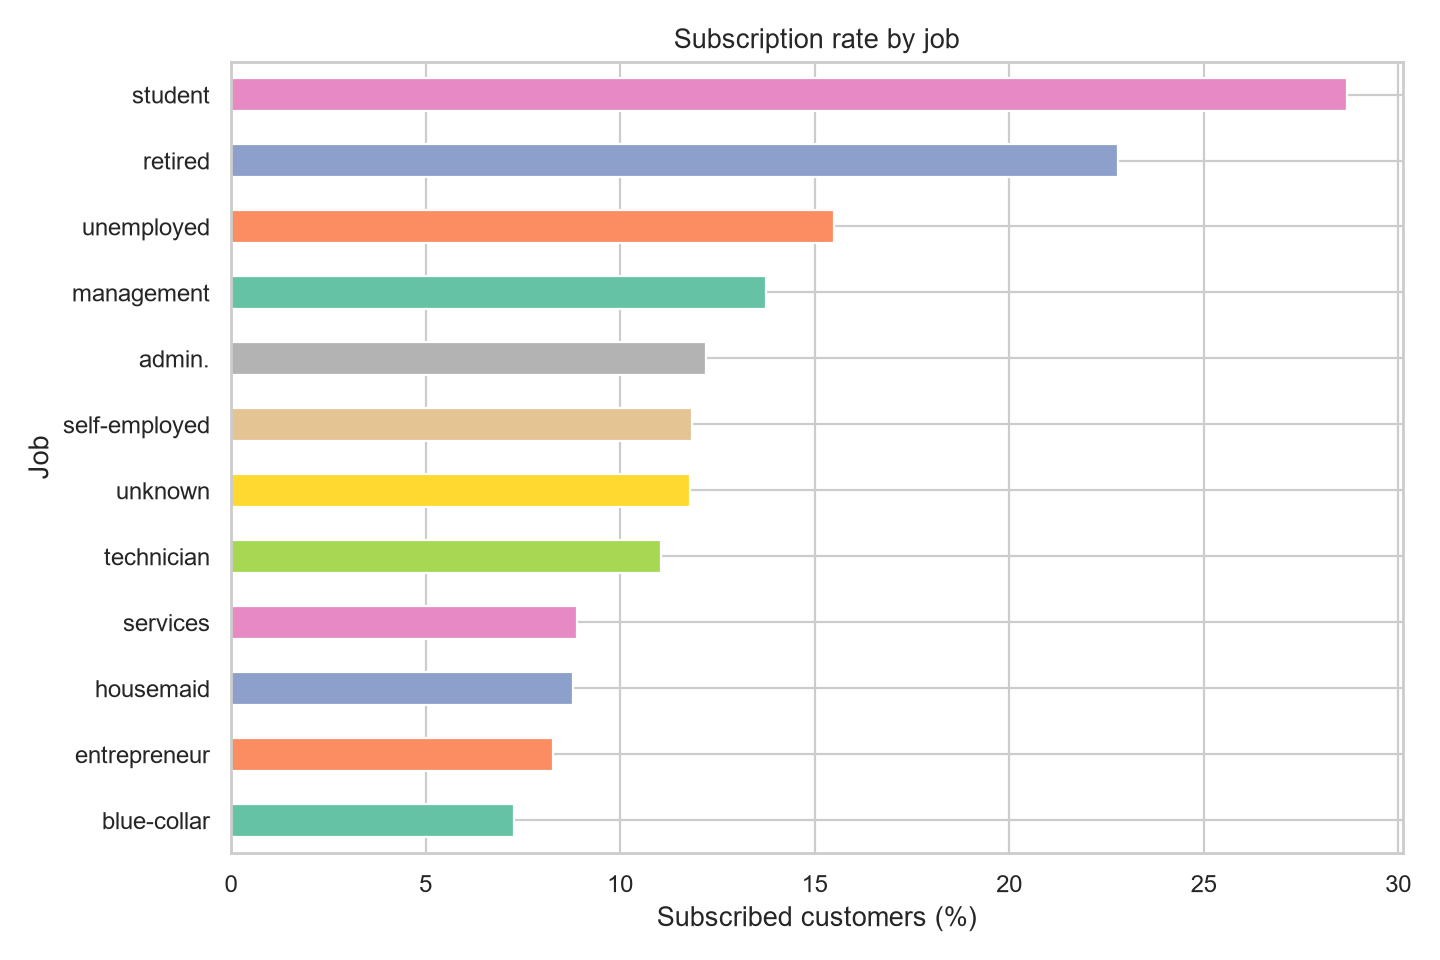

In [3]:
eda_frame = X.copy()
eda_frame['y'] = y.map({0: 'no', 1: 'yes'})
create_eda_plots(eda_frame, 'y', OUTPUT_DIR)
from IPython.display import Image, display
for name in ['target_distribution.png', 'age_vs_subscription.png', 'job_vs_subscription.png']:
    path = OUTPUT_DIR / name
    if path.exists():
        display(Image(filename=str(path)))

## Train and compare models
Preprocessing is fitted within each pipeline to avoid leakage across the stratified train/test split. The winning model is selected by ROC-AUC.

In [4]:
model, comparison, X_test, y_test = train_and_select(X, y, MODEL_DIR, OUTPUT_DIR)
display(comparison)

,model,accuracy,precision,recall,f1,roc_auc
0,random_forest,0.905341,0.589381,0.629490,0.608775,0.931837
1,logistic_regression,0.845737,0.418244,0.814745,0.552741,0.907922


## Evaluate and inspect feature importance
The following report and figures summarize held-out test performance.

,precision,recall,f1-score,support
0,0.950461,0.941891,0.946157,7985.000000
1,0.589381,0.629490,0.608775,1058.000000
accuracy,0.905341,0.905341,0.905341,0.905341
macro avg,0.769921,0.785690,0.777466,9043.000000
weighted avg,0.908216,0.905341,0.906684,9043.000000


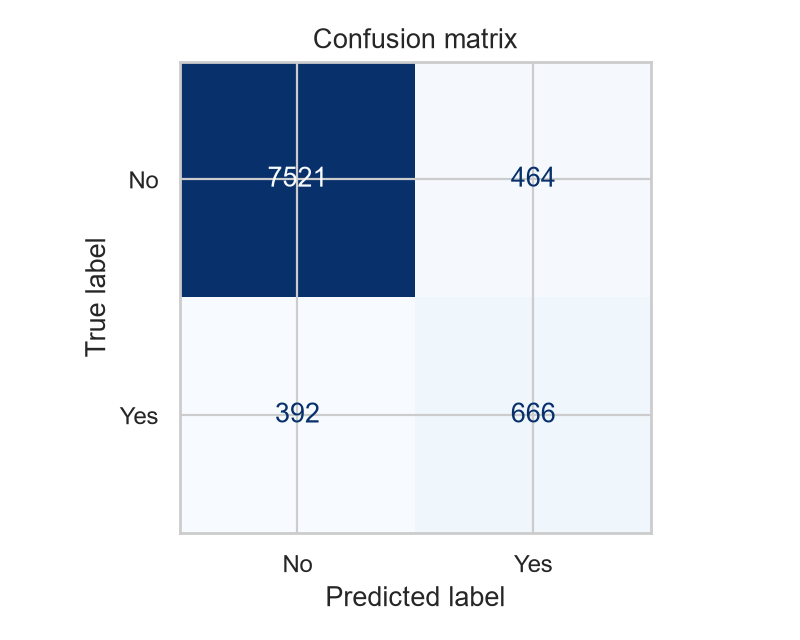

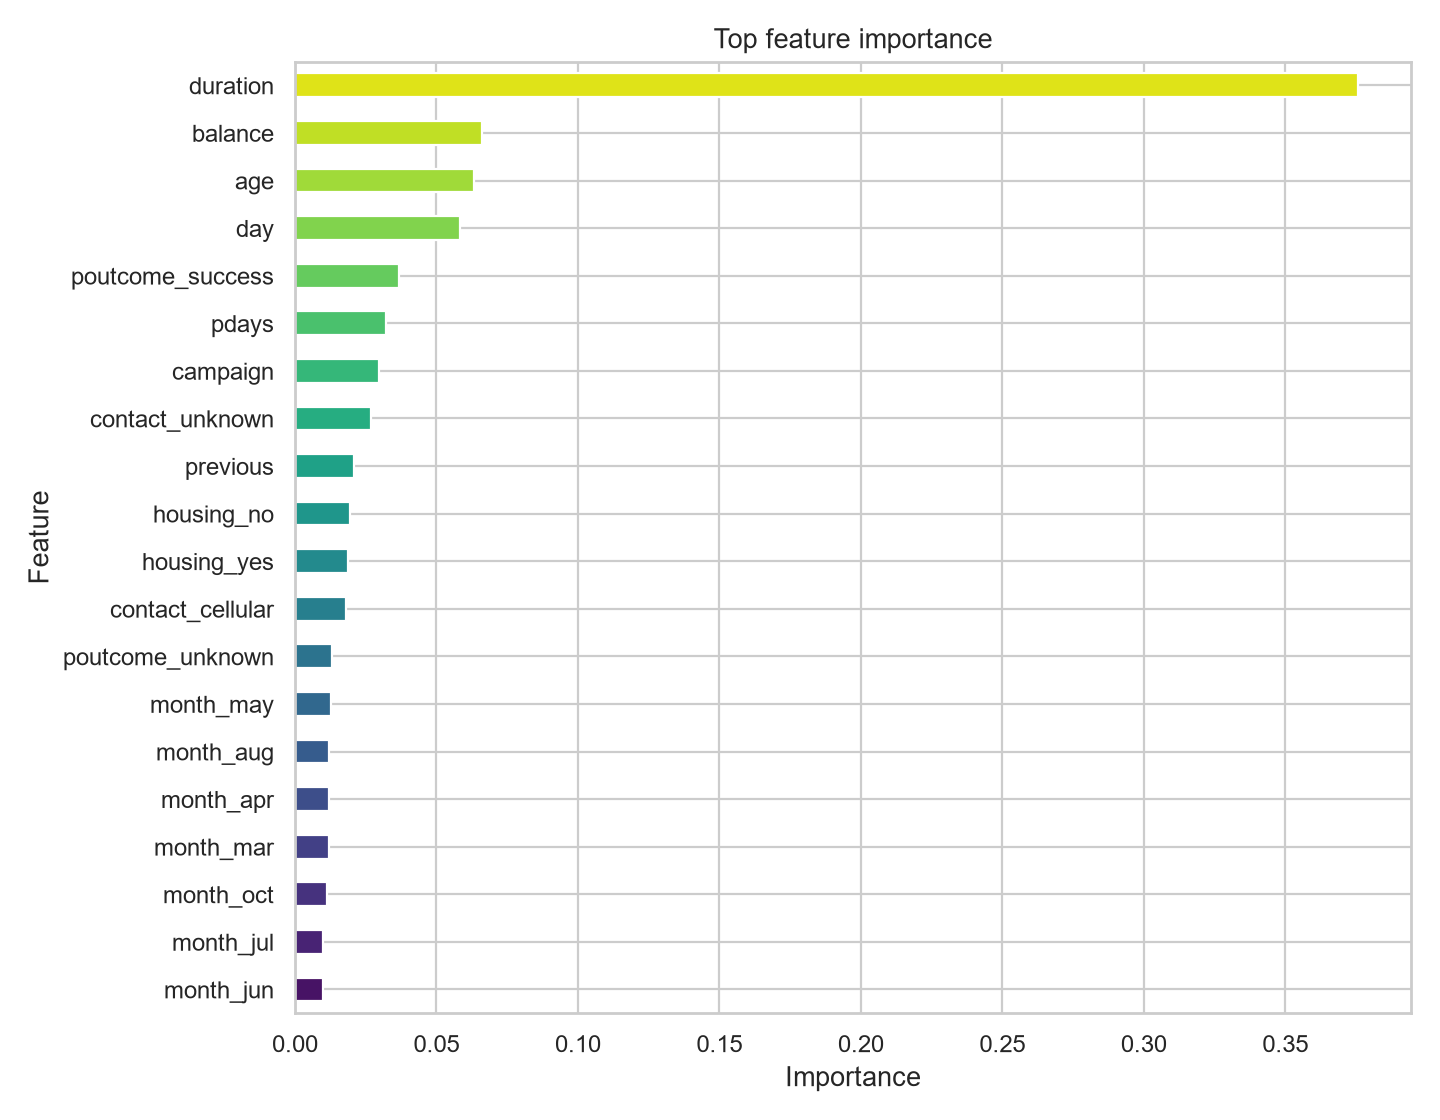

In [5]:
from IPython.display import Image, display
report = evaluate_model(model, X_test, y_test, OUTPUT_DIR)
display(pd.DataFrame(report).T)
for name in ['confusion_matrix.png', 'feature_importance.png']:
    display(Image(filename=str(OUTPUT_DIR / name)))

## Score sample customer records
The stored bundle captures the trained pipeline and expected feature columns. The duration field is available only after a call; remove it before training for true pre-call predictions.

In [6]:
import pickle
with (MODEL_DIR / 'final_model.pkl').open('rb') as file:
    bundle = pickle.load(file)
sample_predictions = predict_records(X_test.head(5), bundle)
display(sample_predictions)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,predicted_subscription,subscription_probability
1392,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,347,2,-1,0,unknown,0,0.010135
7518,44,technician,married,secondary,no,378,yes,no,unknown,30,may,203,2,-1,0,unknown,0,0.017767
12007,31,services,married,secondary,no,356,yes,no,unknown,20,jun,228,5,-1,0,unknown,0,0.019798
5536,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,153,4,-1,0,unknown,0,0.015826
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,61,1,-1,0,unknown,0,0.085610
